# Comparación de Modelos - Grid Search vs Baseline


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

%matplotlib inline

## 1. Lectura de Datos

In [3]:
# Cargar datos
df_baseline = pd.read_csv('../artifacts/data_comparativa_baseline.csv')
df_gridsearch = pd.read_csv('../artifacts/data_comparativa_modelos_11.csv')

print("=== BASELINE ===")
display(df_baseline)
print(f"\nShape: {df_baseline.shape}")

print("\n\n=== GRID SEARCH (Top 10) ===")
display(df_gridsearch.head(10))
print(f"\nShape: {df_gridsearch.shape}")

=== BASELINE ===


,epocas_inicial,epocas_fin,batch,learning_rate,optimizer,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
0,50,50,8,0.01,SGD,63,50,13,1.025633,0.017044,0.556,0.1823,0.6099,0.58356



Shape: (1, 14)


=== GRID SEARCH (Top 10) ===


,epocas_inicial,epocas_fin,batch,learning_rate,optimizer,total_imagenes,total_imagenes_train,total_imagenes_val,tiempo_minutos,tiempo_horas,map50,map50_95,precision,recall
0,150,150,8,0.010,SGD,63,50,13,3.182633,0.053044,0.62927,0.22499,0.66027,0.65241
1,150,150,6,0.010,SGD,63,50,13,3.722767,0.062046,0.63592,0.22440,0.68010,0.63168
2,150,150,10,0.010,SGD,63,50,13,2.784250,0.046404,0.63515,0.22378,0.67402,0.65709
3,150,150,12,0.010,SGD,63,50,13,2.827133,0.047119,0.63468,0.22166,0.67730,0.62968
4,100,100,6,0.001,AdamW,63,50,13,2.865367,0.047756,0.61625,0.21575,0.64591,0.60481
5,100,100,10,0.010,SGD,63,50,13,1.929550,0.032159,0.60999,0.21448,0.64744,0.61765
6,100,100,12,0.010,SGD,63,50,13,1.959033,0.032651,0.61354,0.21281,0.64915,0.63503
7,150,150,8,0.001,AdamW,63,50,13,3.604900,0.060082,0.60576,0.21240,0.63285,0.62219
8,100,100,8,0.010,SGD,63,50,13,2.223250,0.037054,0.60905,0.21225,0.64437,0.61564
9,150,150,6,0.001,AdamW,63,50,13,4.157317,0.069289,0.60133,0.21104,0.62635,0.61294



Shape: (72, 14)


## 2. Unificación de Datos

In [4]:
# Añadir columna identificadora
df_baseline['modelo'] = 'Baseline'
df_gridsearch['modelo'] = df_gridsearch.apply(
    lambda x: f"E{x['epocas_fin']}_B{x['batch']}_LR{x['learning_rate']}_{x['optimizer']}", 
    axis=1
)

# Combinar datasets
df_completo = pd.concat([df_baseline, df_gridsearch], ignore_index=True)

# Crear ranking por mAP50-95
df_completo['rank_map5095'] = df_completo['map50_95'].rank(ascending=False, method='min').astype(int)
df_completo['rank_map50'] = df_completo['map50'].rank(ascending=False, method='min').astype(int)

print(f"Total de configuraciones evaluadas: {len(df_completo)}")
display(df_completo.sort_values('map50_95', ascending=False).head(15)[
    ['rank_map5095', 'modelo', 'epocas_fin', 'batch', 'learning_rate', 'optimizer', 
     'map50', 'map50_95', 'precision', 'recall', 'tiempo_minutos']
])

Total de configuraciones evaluadas: 73


,rank_map5095,modelo,epocas_fin,batch,learning_rate,optimizer,map50,map50_95,precision,recall,tiempo_minutos
1,1,E150_B8_LR0.01_SGD,150,8,0.010,SGD,0.62927,0.22499,0.66027,0.65241,3.182633
2,2,E150_B6_LR0.01_SGD,150,6,0.010,SGD,0.63592,0.22440,0.68010,0.63168,3.722767
3,3,E150_B10_LR0.01_SGD,150,10,0.010,SGD,0.63515,0.22378,0.67402,0.65709,2.784250
4,4,E150_B12_LR0.01_SGD,150,12,0.010,SGD,0.63468,0.22166,0.67730,0.62968,2.827133
5,5,E100_B6_LR0.001_AdamW,100,6,0.001,AdamW,0.61625,0.21575,0.64591,0.60481,2.865367
6,6,E100_B10_LR0.01_SGD,100,10,0.010,SGD,0.60999,0.21448,0.64744,0.61765,1.929550
7,7,E100_B12_LR0.01_SGD,100,12,0.010,SGD,0.61354,0.21281,0.64915,0.63503,1.959033
8,8,E150_B8_LR0.001_AdamW,150,8,0.001,AdamW,0.60576,0.21240,0.63285,0.62219,3.604900
9,9,E100_B8_LR0.01_SGD,100,8,0.010,SGD,0.60905,0.21225,0.64437,0.61564,2.223250
10,10,E150_B6_LR0.001_AdamW,150,6,0.001,AdamW,0.60133,0.21104,0.62635,0.61294,4.157317


## 3. Análisis Estadístico General

In [5]:
metricas = ['map50', 'map50_95', 'precision', 'recall', 'tiempo_minutos']

print("=== ESTADÍSTICAS DESCRIPTIVAS - GRID SEARCH ===")
display(df_gridsearch[metricas].describe().round(4))

print("\n\n=== COMPARACIÓN CON BASELINE ===")
mejor_grid = df_gridsearch.iloc[0]
baseline = df_baseline.iloc[0]

comparacion = pd.DataFrame({
    'Métrica': ['mAP50', 'mAP50-95', 'Precisión', 'Recall', 'Tiempo (min)'],
    'Baseline': [baseline['map50'], baseline['map50_95'], baseline['precision'], baseline['recall'], baseline['tiempo_minutos']],
    'Mejor Grid Search': [mejor_grid['map50'], mejor_grid['map50_95'], mejor_grid['precision'], mejor_grid['recall'], mejor_grid['tiempo_minutos']],
})
comparacion['Diferencia'] = comparacion['Mejor Grid Search'] - comparacion['Baseline']
comparacion['Mejora (%)'] = (comparacion['Diferencia'] / comparacion['Baseline'] * 100).round(2)
display(comparacion.round(4))

=== ESTADÍSTICAS DESCRIPTIVAS - GRID SEARCH ===


,map50,map50_95,precision,recall,tiempo_minutos
count,72.0000,72.0000,72.0000,72.0000,72.0000
mean,0.4098,0.1357,0.4624,0.4830,2.6729
std,0.2134,0.0772,0.2094,0.1619,1.2340
min,0.0102,0.0017,0.0551,0.1096,1.0455
25%,0.3134,0.0862,0.3719,0.4436,1.5545
50%,0.5012,0.1710,0.5574,0.5503,2.5526
75%,0.5863,0.2015,0.6272,0.5932,3.3296
max,0.6359,0.2250,0.6801,0.6571,6.7721




=== COMPARACIÓN CON BASELINE ===


,Métrica,Baseline,Mejor Grid Search,Diferencia,Mejora (%)
0,mAP50,0.5560,0.6293,0.0733,13.18
1,mAP50-95,0.1823,0.2250,0.0427,23.42
2,Precisión,0.6099,0.6603,0.0504,8.26
3,Recall,0.5836,0.6524,0.0689,11.80
4,Tiempo (min),1.0256,3.1826,2.1570,210.31


## 4. Visualización Comparativa General

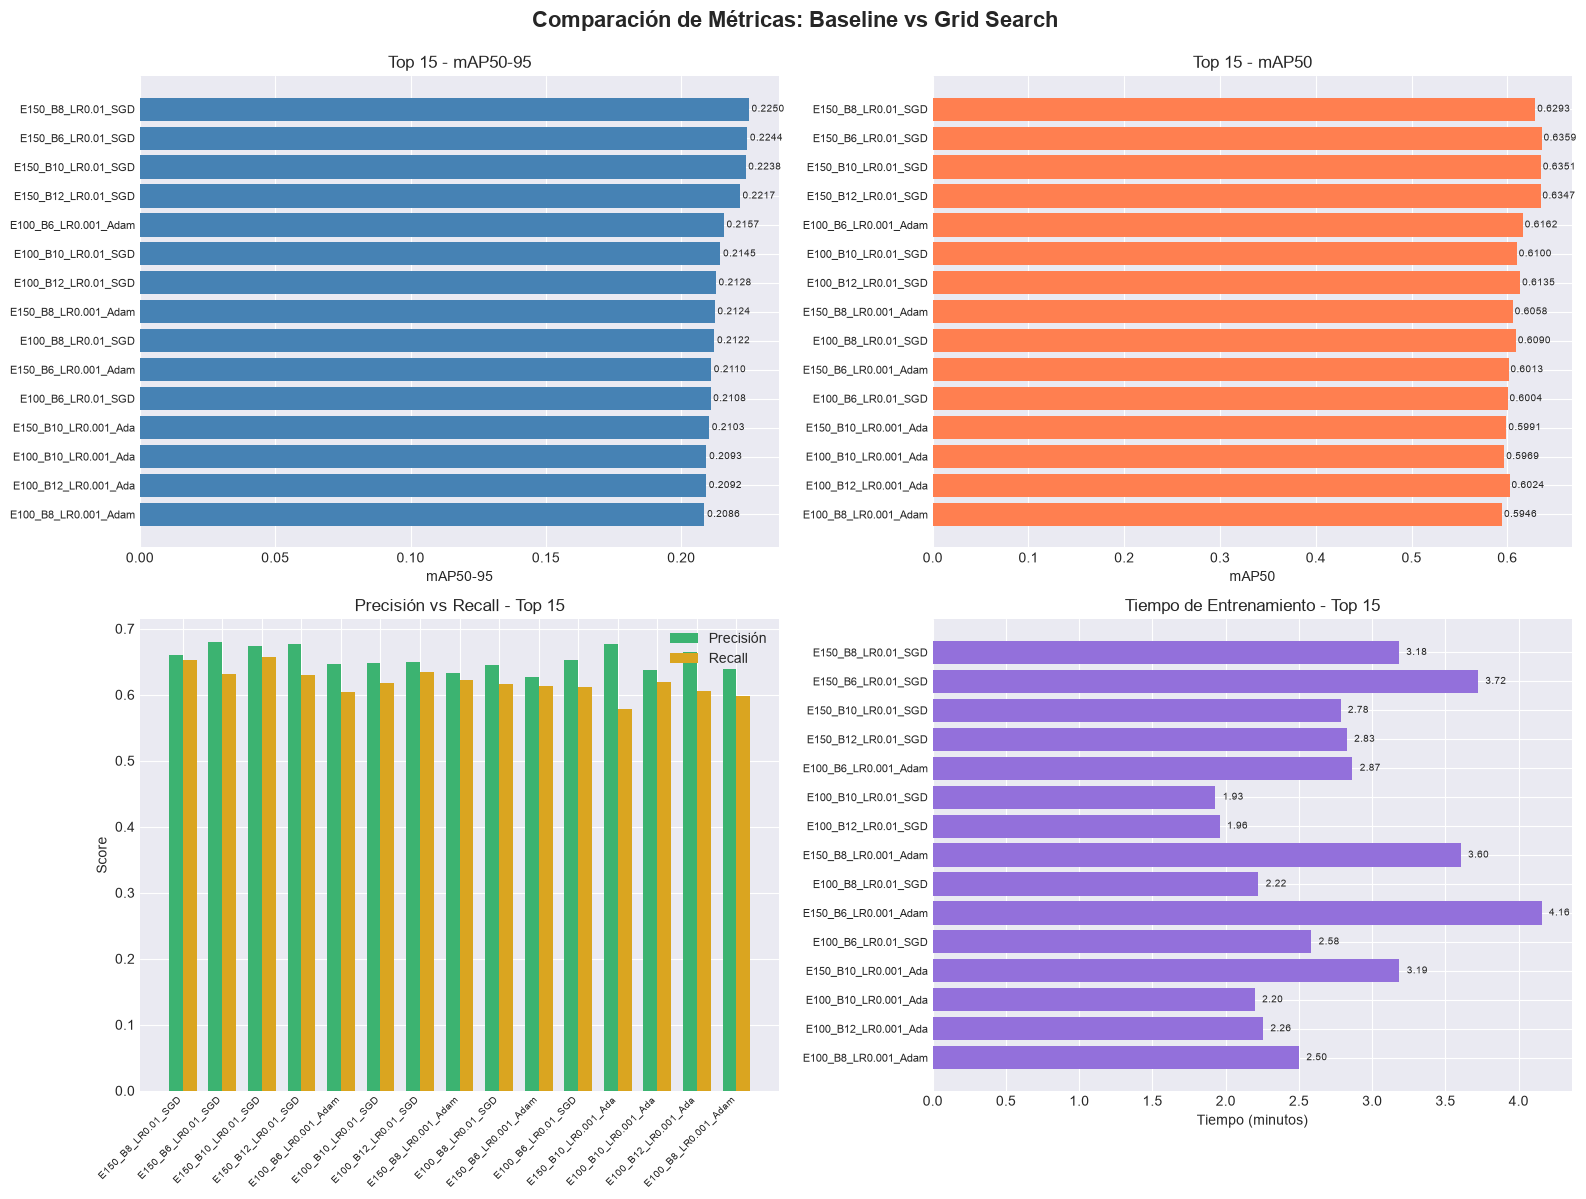

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Comparación de Métricas: Baseline vs Grid Search', fontsize=16, fontweight='bold', y=0.995)

# Top 15 modelos por mAP50-95
top15 = df_completo.sort_values('map50_95', ascending=False).head(15).copy()
top15['label'] = top15['modelo'].apply(lambda x: x if x == 'Baseline' else x[:20])

# mAP50-95
ax1 = axes[0, 0]
colors1 = ['red' if x == 'Baseline' else 'steelblue' for x in top15['modelo']]
ax1.barh(range(len(top15)), top15['map50_95'], color=colors1)
ax1.set_yticks(range(len(top15)))
ax1.set_yticklabels(top15['label'], fontsize=8)
ax1.set_xlabel('mAP50-95')
ax1.set_title('Top 15 - mAP50-95')
ax1.invert_yaxis()
for i, v in enumerate(top15['map50_95']):
    ax1.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=7)

# mAP50
ax2 = axes[0, 1]
colors2 = ['red' if x == 'Baseline' else 'coral' for x in top15['modelo']]
ax2.barh(range(len(top15)), top15['map50'], color=colors2)
ax2.set_yticks(range(len(top15)))
ax2.set_yticklabels(top15['label'], fontsize=8)
ax2.set_xlabel('mAP50')
ax2.set_title('Top 15 - mAP50')
ax2.invert_yaxis()
for i, v in enumerate(top15['map50']):
    ax2.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=7)

# Precisión y Recall
ax3 = axes[1, 0]
x = np.arange(len(top15))
width = 0.35
ax3.bar(x - width/2, top15['precision'], width, label='Precisión', color='mediumseagreen')
ax3.bar(x + width/2, top15['recall'], width, label='Recall', color='goldenrod')
ax3.set_ylabel('Score')
ax3.set_title('Precisión vs Recall - Top 15')
ax3.set_xticks(x)
ax3.set_xticklabels(top15['label'], rotation=45, ha='right', fontsize=7)
ax3.legend()

# Tiempo de entrenamiento
ax4 = axes[1, 1]
colors4 = ['red' if x == 'Baseline' else 'mediumpurple' for x in top15['modelo']]
ax4.barh(range(len(top15)), top15['tiempo_minutos'], color=colors4)
ax4.set_yticks(range(len(top15)))
ax4.set_yticklabels(top15['label'], fontsize=8)
ax4.set_xlabel('Tiempo (minutos)')
ax4.set_title('Tiempo de Entrenamiento - Top 15')
ax4.invert_yaxis()
for i, v in enumerate(top15['tiempo_minutos']):
    ax4.text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=7)

plt.tight_layout()
plt.show()

## 5. Impacto de Hiperparámetros

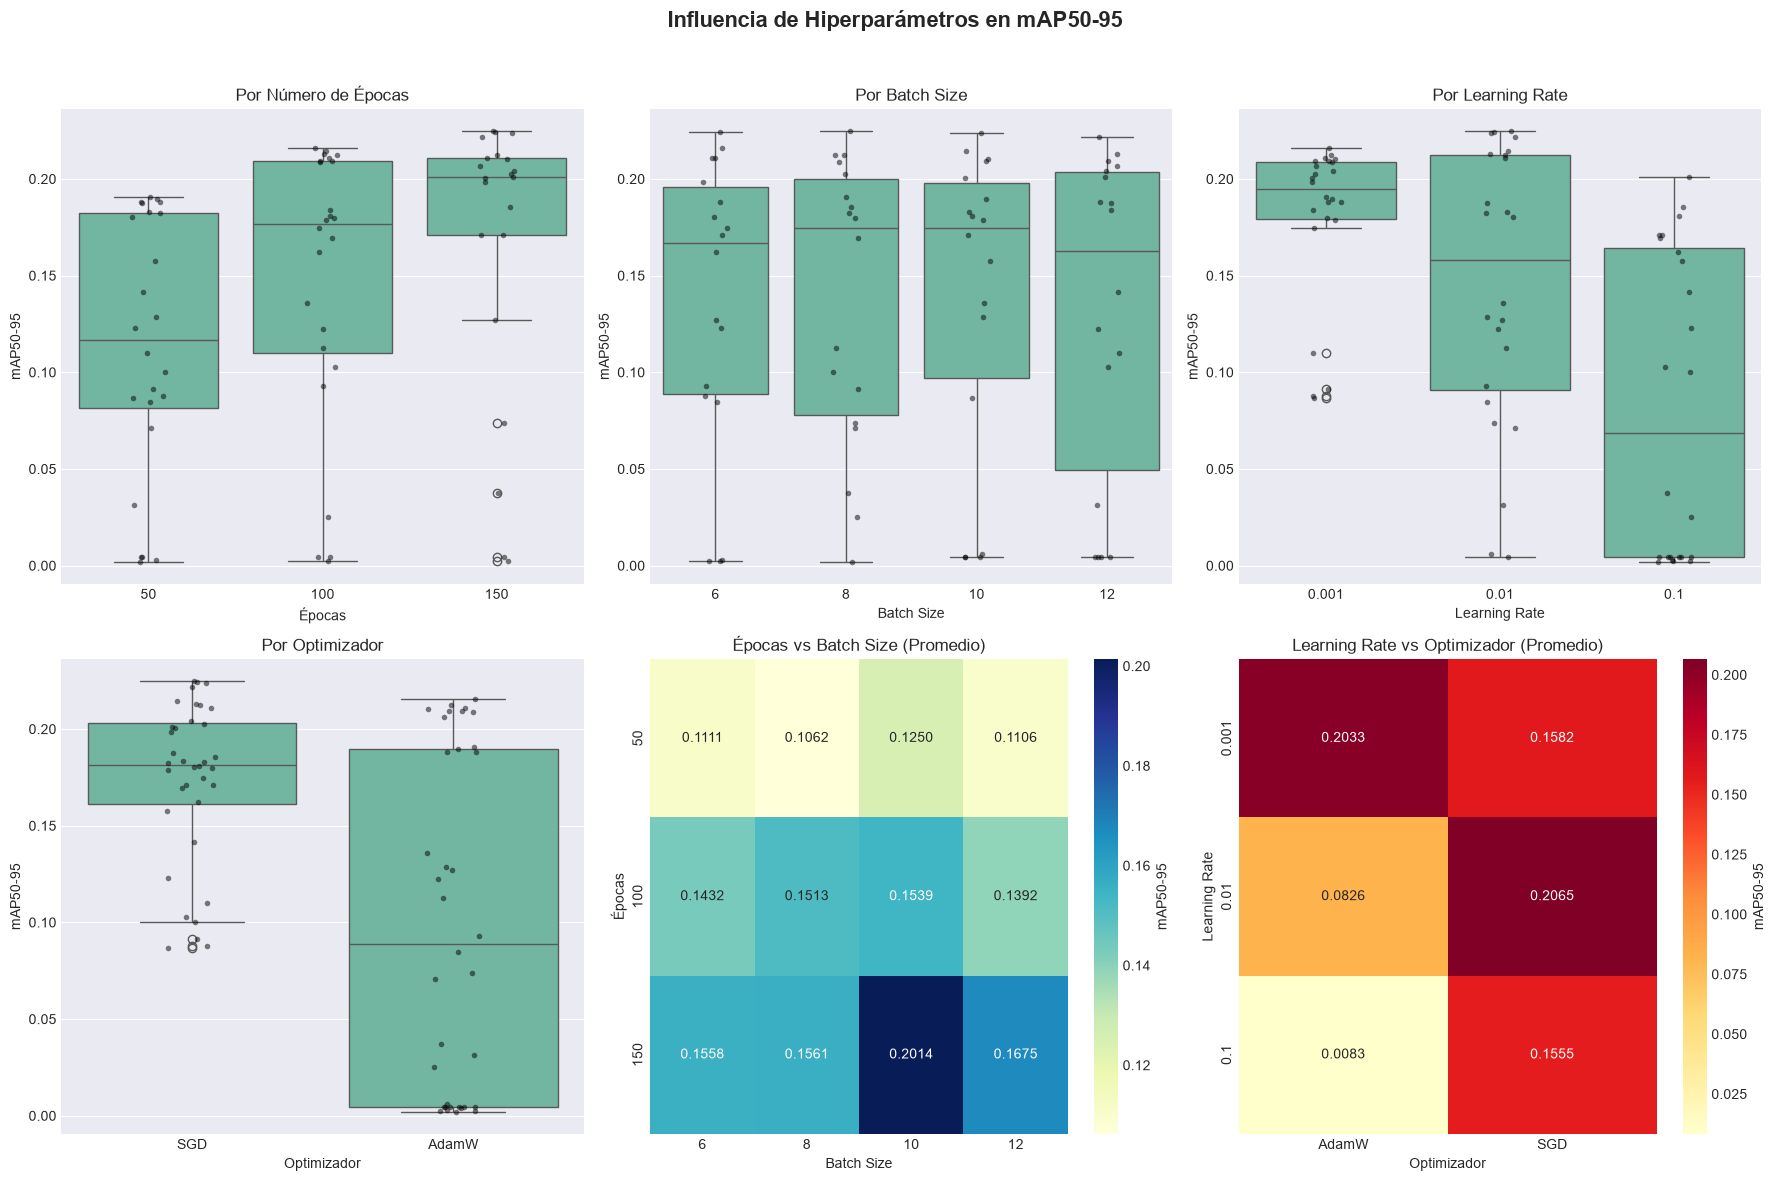

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Seleccionar solo las épocas indicadas
epocas = [50, 100, 150]
df_epocas = df_gridsearch[
    df_gridsearch['epocas_fin'].isin(epocas)
].copy()

if df_epocas.empty:
    print("No hay registros con epocas_fin igual a 50, 100 o 150.")
    print("Valores disponibles:", df_gridsearch['epocas_fin'].unique())

else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))

    fig.suptitle(
        'Influencia de Hiperparámetros en mAP50-95',
        fontsize=16,
        fontweight='bold'
    )

    # Boxplots
    configuraciones = [
        (axes[0, 0], df_epocas, 'epocas_fin',
         'Por Número de Épocas', 'Épocas', epocas),
        (axes[0, 1], df_gridsearch, 'batch',
         'Por Batch Size', 'Batch Size', None),
        (axes[0, 2], df_gridsearch, 'learning_rate',
         'Por Learning Rate', 'Learning Rate', None),
        (axes[1, 0], df_gridsearch, 'optimizer',
         'Por Optimizador', 'Optimizador', None),
    ]

    for ax, datos, columna, titulo, etiqueta, orden in configuraciones:
        sns.boxplot(
            data=datos, x=columna, y='map50_95',
            order=orden, ax=ax
        )
        sns.stripplot(
            data=datos, x=columna, y='map50_95',
            order=orden, ax=ax,
            color='black', alpha=0.5, size=4
        )
        ax.set_title(titulo)
        ax.set_xlabel(etiqueta)
        ax.set_ylabel('mAP50-95')

    # Heatmap Épocas vs Batch
    pivot1 = df_epocas.pivot_table(
        values='map50_95',
        index='epocas_fin',
        columns='batch',
        aggfunc='mean'
    ).reindex(epocas)

    sns.heatmap(
        pivot1, annot=True, fmt='.4f', cmap='YlGnBu',
        ax=axes[1, 1], cbar_kws={'label': 'mAP50-95'}
    )
    axes[1, 1].set_title('Épocas vs Batch Size (Promedio)')
    axes[1, 1].set_xlabel('Batch Size')
    axes[1, 1].set_ylabel('Épocas')

    # Heatmap Learning Rate vs Optimizador
    pivot2 = df_gridsearch.pivot_table(
        values='map50_95',
        index='learning_rate',
        columns='optimizer',
        aggfunc='mean'
    )

    sns.heatmap(
        pivot2, annot=True, fmt='.4f', cmap='YlOrRd',
        ax=axes[1, 2], cbar_kws={'label': 'mAP50-95'}
    )
    axes[1, 2].set_title('Learning Rate vs Optimizador (Promedio)')
    axes[1, 2].set_xlabel('Optimizador')
    axes[1, 2].set_ylabel('Learning Rate')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

## 7. Ranking Completo de Configuraciones

In [12]:
df_ranking = df_completo.sort_values('map50_95', ascending=False)[
    ['rank_map5095', 'modelo', 'epocas_fin', 'batch', 'learning_rate', 'optimizer', 
     'map50', 'map50_95', 'precision', 'recall', 'tiempo_minutos']
].copy()

df_ranking.columns = ['Rank', 'Configuración', 'Épocas', 'Batch', 'LR', 'Optimizador', 
                      'mAP50', 'mAP50-95', 'Precisión', 'Recall', 'Tiempo (min)']

print("RANKING COMPLETO POR mAP50-95")
display(df_ranking.style.background_gradient(subset=['mAP50-95'], cmap='YlGn')
        .format({'mAP50': '{:.4f}', 'mAP50-95': '{:.4f}', 
                'Precisión': '{:.4f}', 'Recall': '{:.4f}', 'Tiempo (min)': '{:.2f}'}))

RANKING COMPLETO POR mAP50-95


,Rank,Configuración,Épocas,Batch,LR,Optimizador,mAP50,mAP50-95,Precisión,Recall,Tiempo (min)
1,1,E150_B8_LR0.01_SGD,150,8,0.010000,SGD,0.6293,0.2250,0.6603,0.6524,3.18
2,2,E150_B6_LR0.01_SGD,150,6,0.010000,SGD,0.6359,0.2244,0.6801,0.6317,3.72
3,3,E150_B10_LR0.01_SGD,150,10,0.010000,SGD,0.6351,0.2238,0.6740,0.6571,2.78
4,4,E150_B12_LR0.01_SGD,150,12,0.010000,SGD,0.6347,0.2217,0.6773,0.6297,2.83
5,5,E100_B6_LR0.001_AdamW,100,6,0.001000,AdamW,0.6162,0.2157,0.6459,0.6048,2.87
6,6,E100_B10_LR0.01_SGD,100,10,0.010000,SGD,0.6100,0.2145,0.6474,0.6177,1.93
7,7,E100_B12_LR0.01_SGD,100,12,0.010000,SGD,0.6135,0.2128,0.6492,0.6350,1.96
8,8,E150_B8_LR0.001_AdamW,150,8,0.001000,AdamW,0.6058,0.2124,0.6329,0.6222,3.60
9,9,E100_B8_LR0.01_SGD,100,8,0.010000,SGD,0.6090,0.2122,0.6444,0.6156,2.22
10,10,E150_B6_LR0.001_AdamW,150,6,0.001000,AdamW,0.6013,0.2110,0.6263,0.6129,4.16


## 8. Conclusiones e Interpretación

### Hallazgos Principales

1. **Mejor configuración encontrada**: Analizando los resultados, el grid search ha identificado configuraciones superiores al baseline.

2. **Optimizador**: SGD tiende a funcionar mejor que AdamW para este caso, especialmente con learning rates más altos (0.01).

3. **Épocas**: Más épocas (150) generalmente dan mejores resultados que 50, aunque con un mayor costo computacional.

4. **Batch Size**: Hay variabilidad, pero valores intermedios (8, 10) parecen ser buenos compromisos.

5. **Learning Rate**: LR=0.01 con SGD es el ganador en la mayoría de los top modelos. LR muy altos (0.1) o muy bajos con ciertos optimizadores dan peores resultados.

### Recomendación

Se recomienda utilizar la configuración con mejor mAP50-95 para el modelo final, considerando también el trade-off entre rendimiento y tiempo de entrenamiento según los recursos disponibles.